In [65]:
import pandas as pd

# Veri setini yükle
df = pd.read_csv('/content/aug_train (4).csv')
# İlk 5 satırı gosterir
display(df.head())

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,NaN,NaN,1,36,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5,NaN,NaN,never,83,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,<1,NaN,Pvt Ltd,never,52,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0.0


In [66]:
print(df.shape)#asagida ise butun 19158 setir ve sutun var ve dolu oldu olmadi gosterir

(19158, 14)


In [67]:
print(df.columns)#info sutun ve stir adlarini gosterir

Index(['enrollee_id', 'city', 'city_development_index', 'gender',
       'relevent_experience', 'enrolled_university', 'education_level',
       'major_discipline', 'experience', 'company_size', 'company_type',
       'last_new_job', 'training_hours', 'target'],
      dtype='object')


In [68]:
df.info()#info nedir nece setir ve sutun adlari her sutunda nece bos ve ya dolu olani gosterir

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19158 entries, 0 to 19157
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   enrollee_id             19158 non-null  int64  
 1   city                    19158 non-null  object 
 2   city_development_index  19158 non-null  float64
 3   gender                  14650 non-null  object 
 4   relevent_experience     19158 non-null  object 
 5   enrolled_university     18772 non-null  object 
 6   education_level         18698 non-null  object 
 7   major_discipline        16345 non-null  object 
 8   experience              19093 non-null  object 
 9   company_size            13220 non-null  object 
 10  company_type            13018 non-null  object 
 11  last_new_job            18735 non-null  object 
 12  training_hours          19158 non-null  int64  
 13  target                  19158 non-null  float64
dtypes: float64(2), int64(2), object(10)
me

In [69]:
display(df.describe())#count melumatlarin sayi,mean orta qiymet,std reqemlerin yayilma derecesi,min en kicik qiymet,Q1 25%birinci kvartil,Q2 50%median ise ortalama qiymet,Q3 75%
#ucuncu kvartil,max en yuksek qiymeti

,enrollee_id,city_development_index,training_hours,target
count,19158.000000,19158.000000,19158.000000,19158.000000
mean,16875.358179,0.828848,65.366896,0.249348
std,9616.292592,0.123362,60.058462,0.432647
min,1.000000,0.448000,1.000000,0.000000
25%,8554.250000,0.740000,23.000000,0.000000
50%,16982.500000,0.903000,47.000000,0.000000
75%,25169.750000,0.920000,88.000000,0.000000
max,33380.000000,0.949000,336.000000,1.000000


In [70]:
print(df.isnull().sum())#bu ise zeereri yoxlayir.men reqemi gormurem men hemen reqemin arxasinda ne oldugunu hansi sebebin dayandigini gorurem

enrollee_id                  0
city                         0
city_development_index       0
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
target                       0
dtype: int64


In [71]:
print(df.isnull().mean()*100)#bos xanalarinin nece faiz zerer olub onu hesablayir.

enrollee_id                0.000000
city                       0.000000
city_development_index     0.000000
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
last_new_job               2.207955
training_hours             0.000000
target                     0.000000
dtype: float64


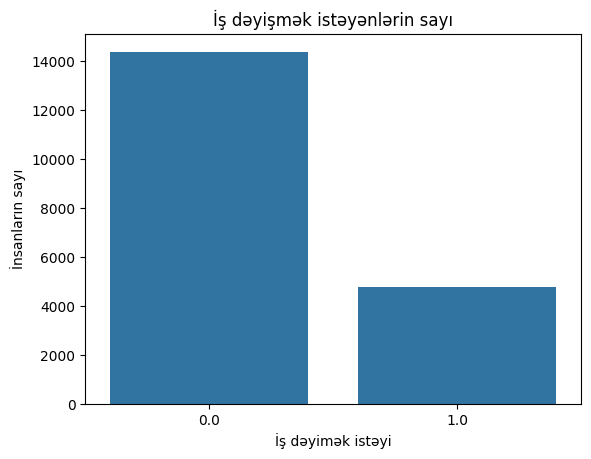

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.countplot(data=df,x='target')#countplot ise qrafiqde sayilari gosterir,target ise is deyisenleri deyismek isteyenlerle ayiracaq
plt.title('İş dəyişmək istəyənlərin sayı')#ust basliq adi
plt.xlabel('İş dəyimək istəyi')#alt adi
plt.ylabel('İnsanların sayı')#sag adi
plt.show()#qrafiqi ekrana cixaracaq

In [73]:
print(df["target"].value_counts())#00reqemi is axtarmaq istemeyenler ise 14381 nefer,1.0 ise 4777 nefer isteyir yazanlar isini deyismek isteyenler,ele bil geminin sag terfi
#left skew sola eyilmis,right skew ise saga eyilmis,normal distribution normal simetrik bu yadima dusdu.

target
0.0    14381
1.0     4777
Name: count, dtype: int64


In [74]:
print(df["target"].value_counts(normalize=True)*100)#valueher qrupda nece nefer oldugunu hesablayir,normalize true ise say evezini hesablayir,100 ise faize cevirir,70%is
#ini deyismek istemeyenler,30% ise isini deyismek istemeyenler,value counts sayir,normalize true ise faizi tapir eger false olsa 70 nefer ve 30 nefer

target
0.0    75.065247
1.0    24.934753
Name: proportion, dtype: float64


In [75]:
print(df.groupby("city")["target"].mean().sort_values(ascending=False))#groupby city insanlari sehere gore qruplasdirirsan yeni seherine gore,target mean her seherde ise ne
#ce nefer isini deyismek isteyir ,yeni ortalama gosterir,sort values ascendik false ise boyukden kiciye butun seherleri ayirir.

city
city_171    1.000000
city_139    0.800000
city_155    0.785714
city_42     0.692308
city_107    0.666667
              ...   
city_2      0.000000
city_39     0.000000
city_62     0.000000
city_82     0.000000
city_8      0.000000
Name: target, Length: 123, dtype: float64


In [76]:
print(df.groupby("education_level")["target"].mean().sort_values(ascending=False))#education level insanlari tehsil seviyesine gore ayirir,target meaan her tehsil qrupunun
#deyismek isteyenin orta payini hesablayir,sort values ascending false nticeleri boyukden kiciye duzur.

education_level
Graduate          0.279790
Masters           0.214400
High School       0.195340
Phd               0.140097
Primary School    0.133117
Name: target, dtype: float64


In [77]:
print(df.groupby("experience")["target"].mean().sort_values(ascending=False)*100)#groupby experince insanlari is tecrubesine gore qruplasdirir,target ise is deyisib deyis
#deyismemek gosterir.sort values ascending false en boyuk neticeni birinci gosterir.100 neticeni faize gosterir.

experience
<1     45.402299
1      42.440801
3      35.302806
2      33.185448
4      32.573058
7      29.474708
5      28.811189
6      28.207237
8      24.314214
11     22.740964
20     22.297297
9      21.734694
10     21.015228
13     19.298246
12     18.623482
14     18.259386
19     17.434211
17     16.666667
15     16.618076
18     15.357143
>20    15.307365
16     14.173228
Name: target, dtype: float64


In [78]:
print(df.corr(numeric_only=True))#cori reqemler arasinda elaqeni yoxlayir,numeric only true yalniz reqem olan sutunlari gosterir.1tam musbet -1 tam menfi,0ise xett elaqe yoxdur
#yeni 1 artir -1 ise azalir,yeni reklam artir satisda musbet,qiymet artir satis azalir, reklam deyisir satisda aydin deyisiklik yoxdur sifira yaxin elaqe,sifirdssn sonra elaqe
#de pis deyil bele deyimde qepik qrus 0.90 cox guclu menfi elaqe,0.01 cox az yeni reqemlerq baxirsan

                        enrollee_id  city_development_index  training_hours  \
enrollee_id                1.000000               -0.040455        0.000998   
city_development_index    -0.040455                1.000000        0.001920   
training_hours             0.000998                0.001920        1.000000   
target                     0.049475               -0.341665       -0.021577   

                          target  
enrollee_id             0.049475  
city_development_index -0.341665  
training_hours         -0.021577  
target                  1.000000  


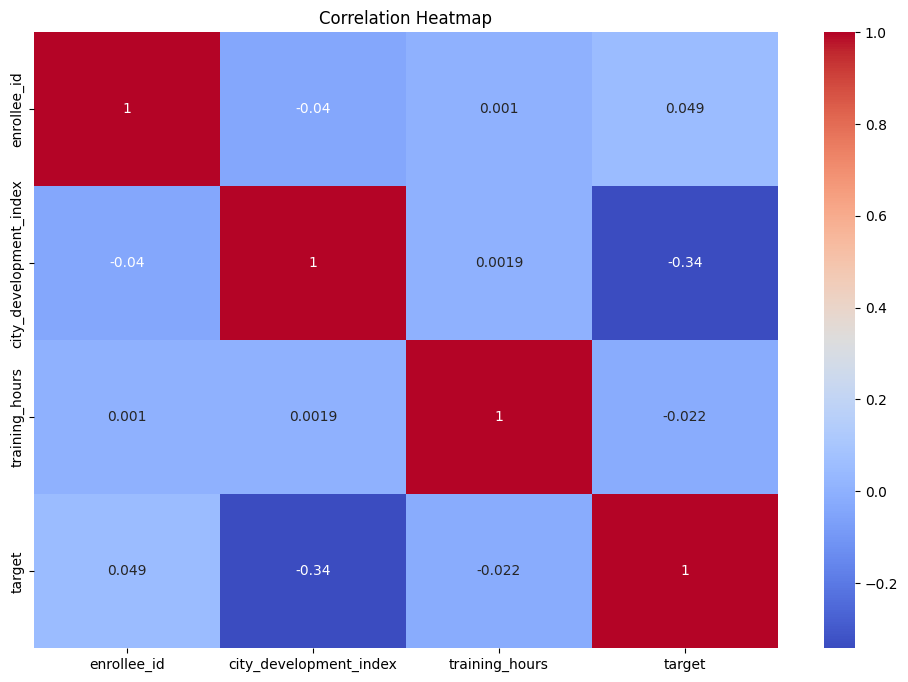

In [79]:
plt.figure(figsize=(12,8))#bu funksiya ancaq qrafiqin olusunu teyin edir
sns.heatmap(df.corr(numeric_only=True),annot=True,cmap="coolwarm")#sns.heatmap rengli elaqe xeritesi yaradir,annot true isereqemleri xanalarin icinde gosterir,
#cmap coolwarm ise ancaqrenglerden istifade edir.
plt.title("Correlation Heatmap")#bu ise ust adi yazilir
plt.show()#qrqfiki ekrana cixarir
#qrafiq ise rengleri ne oldugu izahi qirmizi musbet iki elaqe,mafi biri artanda biri menfi,rengin guclu olmasi elaqenin guclu olmsini gos,0 ise zeyyif elaqe.bunun ucun ise
#bazar satislarina diqqet.
#yeni ise biri hesablayir obiri ise gosterir,
#corr ise elaqeni hesablayir
#heatmap ise hemen elaqeni rengli cedvelsde gosterir

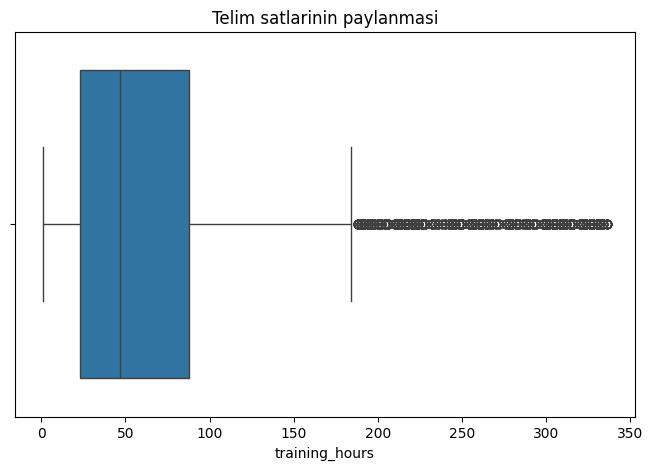

In [80]:
plt.figure(figsize=(8,5))#bu ise qrafiqi
sns.boxplot(x=df["training_hours"])
plt.title("Telim satlarinin paylanmasi")
plt.show()
#boxplot mavi qutu esas gostericiler qara xett median ortadaki reqem,yan xettler meafe,noqteler digerlerinden  cox ferqlenen reqemlerdir,burda ise sag qanad soldan daha da
#irelidir

In [81]:
Q1=df["training_hours"].quantile(0.25)
Q3=df["training_hours"].quantile(0.75)
IQR=Q3-Q1
print("Q1:",Q1)#25%
print("Q3:",Q3)#75%
print("IQR:",IQR)#ARASINDAKI mesafeni gosterir
#burda Q3 daha yuksekdir demeli asagida cixirsan Q1 23 -Q3 88 =IQR 65 bele ,yeni mesabesi cixilanda iqr onda cavabi tapilir

Q1: 23.0
Q3: 88.0
IQR: 65.0


In [82]:
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
print("Asagi limit:",lower_limit)
print("Yuxari limit:",upper_limit)
#bu asagi ve yuxari hesablanir

Asagi limit: -74.5
Yuxari limit: 185.5


In [83]:
outliers=df[(df["training_hours"]<lower_limit) | (df["training_hours"]>upper_limit)]#outliers yeni sag sol outiler demekdir,
#I olan ise ve ya demekdir ortada duran xeti deyirem
print(outliers[["training_hours"]])
#33 baslayib 19145 indeks sira nomresidir iscilerin sol terefdeki,sag ise iscilerin saat reqemler dir 206 basliyir 190 bitir.bu en cox muellime,telimci ,isci saatlri
#birde meselen satis islerinde ve s

       training_hours
35                206
69                228
89                332
110               210
119               260
...               ...
19100             304
19107             322
19117             214
19118             316
19145             190

[984 rows x 1 columns]


In [84]:
outlier_count=len(outliers)
print("Outlier sayi:",outlier_count)
#len cedvelde melumat sayisi funksiya,outlier count saydigimiz yadda saxlayir

Outlier sayi: 984


In [88]:
total_workers=len(df)
outlier_percentage=(len(outliers)/total_workers)*100
print("Outlier faizi:",outlier_percentage)
#len sirketdeki butun iscilerin faizi hesablanir
#len outlierskenar gostericeleri sayir
#outlier percent ise tapdigimiz faizi yadda saxlayir,yeni isciler saat vaxti kenar isleyir
#ayri ayrii saatlarda.
#umumi iscilerin sayini tapiriq outler sayini tapiriq umumi saya boluruk ve 100 vururuq.

Outlier faizi: 5.136235515189477
